# ID estimator calibration on synthetic data

**Question.** At the scale of the real experiment (n = 10k points in D = 4096), how close do TwoNN, GRIDE and ABIDE get to a *known* intrinsic dimension? Cheng et al. report peak IDs of about 35–45 for Llama-3-8B; the ABIDE paper only tests up to d ≈ 15.

**Data.** As in ABIDE §3.1: a d-dimensional standard Gaussian placed in the first d of D = 4096 coordinates, plus isotropic noise (σ = 1e-3) on all coordinates. Real hidden states are not Gaussian, so this is a best case: it shows the estimators' bias from dimension and sample size alone, not from curvature or uneven density.

**Estimators.**
- TwoNN (ML), the ABIDE starting value.
- GRIDE (DADApy `return_id_scaling_gride`), across neighbour scales; the main comparison uses upper rank 32, similar to the scales Cheng chose (their Table C.1).
- ABIDE (`layergeom.abide`, paper defaults: k_max = 350, α = 0.01, 5 iterations).


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from dadapy import Data
from layergeom import abide as ab

# Validated categorical slots 1-3 (dataviz default palette, light mode); fixed order
C = {"TwoNN": "#2a78d6", "GRIDE": "#eb6834", "ABIDE": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "lines.linewidth": 2})

D, NOISE, SEED = 4096, 1e-3, 0
GRIDE_RANGE = 2**9   # largest neighbour rank for the GRIDE scale sweep
GRIDE_RANK = 32      # scale used in the main comparison

def gaussian(n, d, D=D, noise=NOISE, seed=SEED):
    rng = np.random.default_rng(seed + 1000 * d + n)
    X = np.zeros((n, D), dtype=np.float32)
    X[:, :d] = rng.standard_normal((n, d))
    X += noise * rng.standard_normal((n, D)).astype(np.float32)
    return X

def run_all(X):
    t0 = time.time()
    dist, idx = ab.neighbours(X, k_max=350)
    r = ab.abide(dist=dist, idx=idx)
    data = Data(X.astype(np.float64), maxk=GRIDE_RANGE, verbose=False)
    ids, errs, ranks = data.return_id_scaling_gride(range_max=GRIDE_RANGE, return_ranks=True)
    g = dict(zip(ranks, zip(ids, errs)))
    return {"TwoNN": r.id_2nn, "ABIDE": r.id, "ABIDE_se": r.se, "kstar": r.kstar.mean(),
            "GRIDE": g[GRIDE_RANK][0], "GRIDE_se": g[GRIDE_RANK][1],
            "gride_ranks": np.array(ranks), "gride_ids": np.array(ids),
            "secs": time.time() - t0}


/Users/mateuszjarek/Documents/Thesis/code/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Estimate versus true dimension (n = 10,000)

In [2]:
DIMS = [5, 10, 20, 30, 40, 50, 60]
res = {}
for d in DIMS:
    res[d] = run_all(gaussian(10_000, d))
    r = res[d]
    print(f"d={d:>2}  TwoNN {r['TwoNN']:6.2f}  GRIDE@{GRIDE_RANK} {r['GRIDE']:6.2f}  "
          f"ABIDE {r['ABIDE']:6.2f} ± {r['ABIDE_se']:.2f}  mean k* {r['kstar']:5.1f}  ({r['secs']:.0f}s)")


d= 5  TwoNN   5.45  GRIDE@32   5.10  ABIDE   4.95 ± 0.02  mean k*  15.9  (22s)


d=10  TwoNN   9.99  GRIDE@32   9.31  ABIDE   9.22 ± 0.05  mean k*   7.0  (18s)


d=20  TwoNN  17.80  GRIDE@32  15.87  ABIDE  16.43 ± 0.10  mean k*   4.9  (19s)


d=30  TwoNN  24.03  GRIDE@32  20.92  ABIDE  22.14 ± 0.15  mean k*   4.3  (20s)


d=40  TwoNN  29.43  GRIDE@32  25.27  ABIDE  27.37 ± 0.19  mean k*   4.2  (15s)


d=50  TwoNN  34.91  GRIDE@32  29.00  ABIDE  32.60 ± 0.24  mean k*   3.9  (16s)


d=60  TwoNN  39.11  GRIDE@32  32.62  ABIDE  36.06 ± 0.26  mean k*   3.9  (19s)


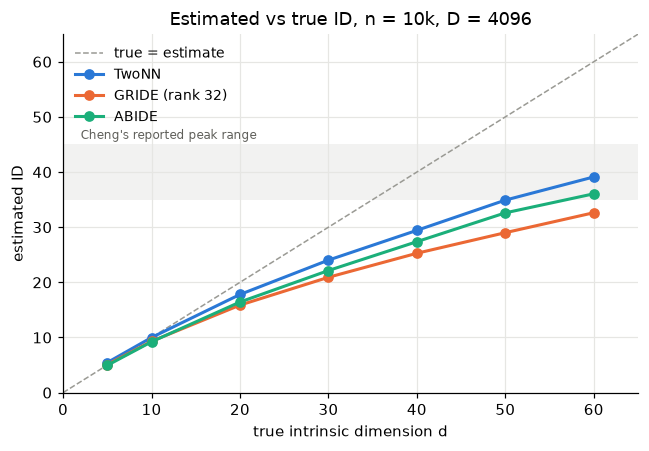

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot([0, 65], [0, 65], color="#9a9a94", lw=1, ls="--", label="true = estimate")
for name in ["TwoNN", "GRIDE", "ABIDE"]:
    ax.plot(DIMS, [res[d][name] for d in DIMS], marker="o", ms=6, color=C[name],
            label=name if name != "GRIDE" else f"GRIDE (rank {GRIDE_RANK})")
ax.axhspan(35, 45, color="#9a9a94", alpha=0.12, lw=0)
ax.text(2, 46, "Cheng's reported peak range", fontsize=8, color="#5f5f5a")
ax.set(xlabel="true intrinsic dimension d", ylabel="estimated ID", xlim=(0, 65), ylim=(0, 65),
       title="Estimated vs true ID, n = 10k, D = 4096")
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()


## 2. GRIDE across scales

Each line is one true d. A flat stretch is the plateau Cheng used to choose the scale; on clean data it should sit at the true d.

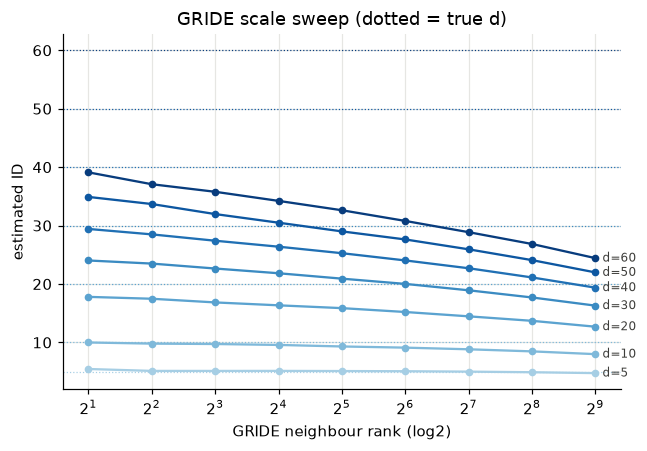

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.2))
blues = plt.cm.Blues(np.linspace(0.35, 0.95, len(DIMS)))
for c, d in zip(blues, DIMS):
    ax.plot(res[d]["gride_ranks"], res[d]["gride_ids"], marker="o", ms=4, color=c, lw=1.5)
    ax.axhline(d, color=c, lw=0.8, ls=":")
    ax.text(res[d]["gride_ranks"][-1] * 1.08, res[d]["gride_ids"][-1], f"d={d}", va="center", fontsize=8, color="#3d3d3a")
ax.set_xscale("log", base=2)
ax.set(xlabel="GRIDE neighbour rank (log2)", ylabel="estimated ID", title="GRIDE scale sweep (dotted = true d)")
plt.tight_layout(); plt.show()


## 3. Sample size at d = 40

How much of the bias at Cheng-like dimensions is due to n? (Cheng: n = 10k per partition.)

n=  2500  TwoNN  27.57  GRIDE@32  22.71  ABIDE  25.83  mean k*   4.2
n=  5000  TwoNN  29.51  GRIDE@32  24.15  ABIDE  27.27  mean k*   4.2
n= 10000  TwoNN  29.43  GRIDE@32  25.27  ABIDE  27.37  mean k*   4.2
n= 20000  TwoNN  30.47  GRIDE@32  26.35  ABIDE  28.16  mean k*   4.1


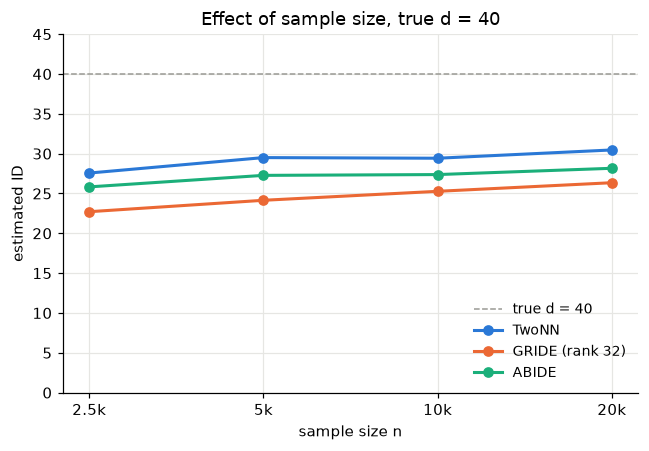

In [5]:
NS = [2_500, 5_000, 10_000, 20_000]
res_n = {n: run_all(gaussian(n, 40)) for n in NS}
for n in NS:
    r = res_n[n]
    print(f"n={n:>6}  TwoNN {r['TwoNN']:6.2f}  GRIDE@{GRIDE_RANK} {r['GRIDE']:6.2f}  ABIDE {r['ABIDE']:6.2f}  mean k* {r['kstar']:5.1f}")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.axhline(40, color="#9a9a94", lw=1, ls="--", label="true d = 40")
for name in ["TwoNN", "GRIDE", "ABIDE"]:
    ax.plot(NS, [res_n[n][name] for n in NS], marker="o", ms=6, color=C[name],
            label=name if name != "GRIDE" else f"GRIDE (rank {GRIDE_RANK})")
ax.set_xscale("log")
ax.set_xticks(NS, [f"{n/1000:g}k" for n in NS]); ax.minorticks_off()
ax.set(xlabel="sample size n", ylabel="estimated ID", ylim=(0, 45), title="Effect of sample size, true d = 40")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()


## Notes

- Fill in after reading the outputs: which estimator is least biased at d ≈ 35–45, whether the bias is monotone in d (so layer *profiles* keep their shape even if absolute values are off), and how much a larger n helps.
- Limits: Gaussian data with uniform noise only. Real hidden states have uneven density, outlier dimensions and growing norms, which this does not test.
